# Greedy Heuristic

In [1]:
import pandas as pd
import numpy as np
import math
import random
import matplotlib.pyplot as plt
import collections

#Make sure its the same!!
random.seed(1)
np.random.seed(1)

# Parameters
data = pd.read_csv('data/tampines_busstoploc.csv')  
stops = data['Number'].tolist()
n = len(stops)  
s=0
t=0

#Transform to coordinates from csv
coord_x = data['Longitude'].to_numpy()
coord_y = data['Latitude'].to_numpy()

distancelct = np.empty([n, n])
for i in range(n):
    for j in range(n):
        distancelct[i, j] = math.sqrt((coord_x[i] - coord_x[j])**2 + (coord_y[i] - coord_y[j])**2)
distancelct[np.diag_indices_from(distancelct)] = 99999  # no self loops

# Initialize dictionary for roles
stop_roles = {}

# Assign fixed roles to first and last stops
stop_roles[stops[0]] = 'O'       # First stop is always Origin
stop_roles[stops[-1]] = 'D'      # Last stop is always Destination

# Assign random roles to intermediate stops
for stop in stops[1:-1]:
    stop_roles[stop] = random.choices(['O', 'D', 'OD'], weights=[0.4, 0.4, 0.2])[0]

print(stop_roles)


# Initialize number of passengers
num_passengers = 200

# Define origins and destinations based on stop roles
origins = [i for i in stops if stop_roles[i] in ('O', 'OD')]  # Origin or OD stop
destinations = [i for i in stops if stop_roles[i] in ('D', 'OD')]  # Destination or OD stop

# Initialize trip_counts dictionary to count trips between origin and destination pairs
trip_counts = {}

# Generate trips for passengers (only one loop needed now)
for _ in range(num_passengers):
    o = random.choice(origins)
    d = random.choice(destinations)
    
    while d == o:  # Ensure origin and destination are not the same
        d = random.choice(destinations)
    
    # Update trip count for the OD pair
    if (o, d) in trip_counts:
        trip_counts[(o, d)] += 1
    else:
        trip_counts[(o, d)] = 1

# Create OD pairs from trip_counts (only those with non-zero trips)
od_pairs = [pair for pair, count in trip_counts.items() if count > 0]

# Print for debugging
print("Trip Counts:", trip_counts)
print("OD Pairs:", od_pairs)

{0: 'O', 79: 'D', 1: 'O', 2: 'OD', 3: 'D', 4: 'O', 5: 'D', 6: 'D', 7: 'D', 8: 'D', 9: 'O', 10: 'O', 11: 'OD', 12: 'D', 13: 'D', 14: 'O', 15: 'D', 16: 'D', 17: 'O', 18: 'OD', 19: 'OD', 20: 'O', 21: 'O', 22: 'D', 23: 'OD', 24: 'O', 25: 'O', 26: 'D', 27: 'O', 28: 'O', 29: 'D', 30: 'D', 31: 'O', 32: 'O', 33: 'O', 34: 'D', 35: 'O', 36: 'O', 37: 'OD', 38: 'D', 39: 'D', 40: 'O', 41: 'OD', 42: 'OD', 43: 'O', 44: 'O', 45: 'D', 46: 'D', 47: 'OD', 48: 'D', 49: 'OD', 50: 'D', 51: 'O', 52: 'D', 53: 'OD', 54: 'OD', 55: 'D', 56: 'D', 57: 'O', 58: 'O', 59: 'D', 60: 'D', 61: 'O', 62: 'D', 63: 'D', 64: 'D', 65: 'O', 66: 'D', 67: 'D', 68: 'D', 69: 'D', 70: 'O', 71: 'D', 72: 'O', 73: 'O', 74: 'D', 75: 'OD', 76: 'D', 77: 'O', 78: 'O'}
Trip Counts: {(53, 23): 1, (0, 19): 1, (57, 59): 1, (24, 46): 1, (53, 41): 1, (61, 41): 1, (47, 30): 1, (77, 59): 1, (70, 75): 1, (0, 45): 1, (53, 13): 1, (54, 59): 1, (23, 48): 1, (4, 52): 1, (37, 60): 1, (58, 19): 1, (53, 47): 1, (51, 41): 1, (42, 41): 1, (0, 56): 1, (57, 6

In [2]:
def greedy_tsp(dist_matrix, stop_types, n):
    current_stop_a = 0  # Depot
    current_stop_b = 0  # Depot
    bus_a_route = [current_stop_a]
    bus_b_route = [current_stop_b]
    
    remaining_stops = set(range(1, n))  # All non-depot stops
    visited_by_a = set()
    visited_by_b = set()
    
    while remaining_stops:
        # Bus A selects closest remaining stop
        best_a = None
        min_dist_a = float('inf')
        for stop in remaining_stops:
            dist = dist_matrix[current_stop_a][stop]
            if dist < min_dist_a:
                best_a = stop
                min_dist_a = dist
        
        if best_a is not None:
            bus_a_route.append(best_a)
            visited_by_a.add(best_a)
            # Only remove if:
            # - It's not an OD stop, OR
            # - It's an OD stop already visited by Bus B
            if stop_types[best_a] != 'OD' or (best_a in visited_by_b):
                remaining_stops.remove(best_a)
            current_stop_a = best_a
        
        # Bus B selects closest remaining stop
        best_b = None
        min_dist_b = float('inf')
        for stop in remaining_stops:
            dist = dist_matrix[current_stop_b][stop]
            if dist < min_dist_b:
                best_b = stop
                min_dist_b = dist
        
        if best_b is not None:
            bus_b_route.append(best_b)
            visited_by_b.add(best_b)
            # Only remove if:
            # - It's not an OD stop, OR
            # - It's an OD stop already visited by Bus A
            if stop_types[best_b] != 'OD' or (best_b in visited_by_a):
                remaining_stops.remove(best_b)
            current_stop_b = best_b
    
    # Return to depot
    bus_a_route.append(0)
    bus_b_route.append(0)
    
    return bus_a_route, bus_b_route

bus_a_route, bus_b_route = greedy_tsp(distancelct, od_pairs, n)
print(bus_a_route, bus_b_route)

[0, 64, 12, 42, 40, 69, 17, 68, 32, 46, 34, 54, 71, 72, 76, 22, 24, 29, 25, 6, 77, 21, 58, 53, 15, 8, 65, 2, 10, 11, 14, 38, 62, 16, 50, 51, 33, 45, 47, 41, 48, 0] [0, 63, 74, 78, 55, 3, 20, 52, 13, 30, 28, 44, 61, 27, 66, 60, 37, 36, 67, 70, 1, 43, 18, 31, 5, 26, 57, 56, 9, 23, 73, 35, 39, 4, 79, 7, 19, 49, 59, 75, 0]


In [3]:
def calculate_route_distance(route_indices, dist_matrix):
    total_distance = 0.0
    for i in range(len(route_indices) - 1):
        from_stop_idx = route_indices[i]
        to_stop_idx = route_indices[i+1]
        total_distance += dist_matrix[from_stop_idx, to_stop_idx]
    return total_distance
distance_a=calculate_route_distance(bus_a_route, distancelct)
distance_b=calculate_route_distance(bus_b_route, distancelct)
distance_total=distance_a+distance_b
print(distance_a,distance_b,distance_total)


0.1612890934655859 0.14834272570435295 0.30963181916993887


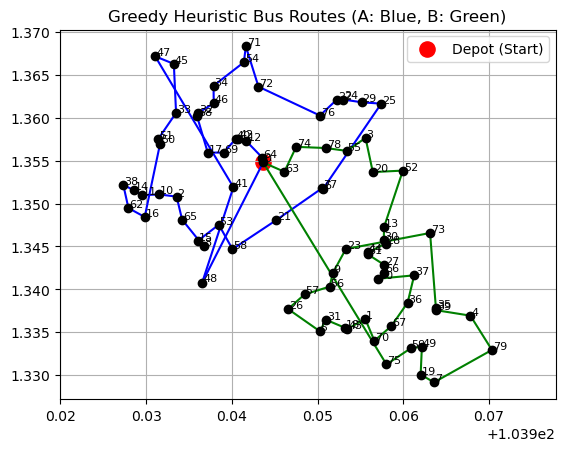

In [4]:
#Plotting

def connectpoints(x, y, p1, p2, color):
    plt.plot([x[p1], x[p2]], [y[p1], y[p2]], color=color)

for i in range(len(bus_a_route) - 1):
    connectpoints(coord_x, coord_y, bus_a_route[i], bus_a_route[i + 1], 'blue')  # Blue for Bus A

for i in range(len(bus_b_route) - 1):
    connectpoints(coord_x, coord_y, bus_b_route[i], bus_b_route[i + 1], 'green')  # Green for Bus B

plt.plot(coord_x, coord_y, 'ko')  
plt.scatter(coord_x[s], coord_y[s], color='red', s=120, label="Depot (Start)")  # Red marker for the depot (start stop)

for idx, (x, y) in enumerate(zip(coord_x, coord_y)):
    plt.text(x + 0.0001, y + 0.0001, str(idx), fontsize=8)

plt.title("Greedy Heuristic Bus Routes (A: Blue, B: Green)")
plt.axis('equal')  # Equal scaling of x and y axes
plt.grid(True)  # Enable grid for better visibility
plt.legend()  # Show legend for depot
plt.show()


# K-opt operators

In [5]:
#K-OPT operators

def two_opt_swap(route_indices, i, k):
    # Ensure i < k
    if i > k: i, k = k, i

    new_route = route_indices[:i] + route_indices[k:i-1:-1] + route_indices[k+1:]
    return new_route

def two_opt(initial_route_indices, dist_matrix):
    current_route = list(initial_route_indices) # Make a copy to avoid modifying original
    best_distance = calculate_route_distance(current_route, dist_matrix)
    n_route_nodes = len(current_route) # Moved definition here

    improved = True

    while improved:
        improved = False
        if n_route_nodes < 4: # Cannot perform a meaningful 2-opt for [depot, A, B, depot]
            break

        # Iterate through all possible pairs (i, k) for 2-opt swap
        # The loops ensure i and k are valid indices for a swap, excluding the depot.
        # Indices 1 to n_route_nodes - 2 represent the internal stops.
        for i in range(1, n_route_nodes - 2): # First cut point (before node i)
            for k in range(i + 1, n_route_nodes - 1): # Second cut point (before node k)
                new_route = two_opt_swap(current_route, i, k)
                new_distance = calculate_route_distance(new_route, dist_matrix)

                if new_distance < best_distance:
                    current_route = new_route
                    best_distance = new_distance
                    improved = True
                    break
            if improved:
                break
    return current_route, best_distance

def three_opt_swap(route_indices, i, j, k, case):
    # Ensure i < j < k
    indices = sorted([i, j, k])
    i, j, k = indices[0], indices[1], indices[2]

    # Segments based on cut points
    A = route_indices[0:i+1]
    B = route_indices[i+1:j+1]
    C = route_indices[j+1:k+1]
    D = route_indices[k+1:]

    # Cases for 3-opt (non-trivial permutations)
    if case == 1: # A-C-B-D
        return A + C + B + D
    elif case == 2: # A-B'-C'-D (where B' and C' are reversed)
        return A + B[::-1] + C[::-1] + D
    elif case == 3: # A-C'-B-D
        return A + C[::-1] + B + D
    elif case == 4: # A-B-C'-D
        return A + B + C[::-1] + D
    else:
        return route_indices # Should not happen

def three_opt(initial_route_indices, dist_matrix):
    current_route = list(initial_route_indices) # Make a copy
    best_distance = calculate_route_distance(current_route, dist_matrix)
    n_route_nodes = len(current_route) # Moved definition here

    improved = True

    while improved:
        improved = False
        if n_route_nodes < 6: # Need at least 6 nodes for a meaningful 3-opt swap
            break

        for i in range(1, n_route_nodes - 4): # First cut point
            for j in range(i + 1, n_route_nodes - 3): # Second cut point
                for k in range(j + 1, n_route_nodes - 2): # Third cut point
                    # Test 4 non-trivial 3-opt cases
                    for case in range(1, 5):
                        new_route = three_opt_swap(current_route, i, j, k, case)
                        new_distance = calculate_route_distance(new_route, dist_matrix)

                        if new_distance < best_distance:
                            current_route = new_route
                            best_distance = new_distance
                            improved = True
                            break
                    if improved: break
                if improved: break
            if improved: break
    return current_route, best_distance


## k-opt optimised A and B route

In [6]:
# Apply 2-opt to Bus A's route
optimized_route_a_2opt, dist_a_2opt = two_opt(bus_a_route, distancelct)
print(f"Bus A after 2-opt: {optimized_route_a_2opt} (Distance: {dist_a_2opt:.5f})")

# Apply 2-opt to Bus B's route
optimized_route_b_2opt, dist_b_2opt = two_opt(bus_b_route, distancelct)
print(f"Bus B after 2-opt: {optimized_route_b_2opt} (Distance: {dist_b_2opt:.5f})")

# Apply 3-opt to Bus A's route
optimized_route_a_3opt, dist_a_3opt = three_opt(bus_a_route, distancelct)
print(f"Bus A after 3-opt: {optimized_route_a_3opt} (Distance: {dist_a_3opt:.5f})")

# Apply 3-opt to Bus B's route
optimized_route_b_3opt, dist_b_3opt = three_opt(bus_b_route, distancelct)
print(f"Bus B after 3-opt: {optimized_route_b_3opt} (Distance: {dist_b_3opt:.5f})")

#optimised distance
opti_distance_total=  dist_a_2opt+dist_b_2opt
print(dist_a_2opt,dist_b_2opt,opti_distance_total)

Bus A after 2-opt: [0, 64, 12, 42, 40, 46, 34, 71, 54, 72, 76, 22, 24, 29, 25, 6, 77, 21, 41, 53, 58, 48, 8, 15, 65, 2, 10, 11, 16, 62, 14, 38, 50, 51, 33, 47, 45, 32, 68, 17, 69, 0] (Distance: 0.13794)
Bus B after 2-opt: [0, 63, 9, 56, 57, 26, 5, 31, 18, 43, 70, 75, 59, 49, 19, 7, 79, 4, 39, 35, 73, 37, 36, 67, 1, 23, 44, 61, 60, 66, 27, 28, 30, 13, 52, 20, 3, 55, 78, 74, 0] (Distance: 0.13680)
Bus A after 3-opt: [0, 64, 12, 42, 40, 69, 17, 41, 21, 77, 6, 25, 29, 24, 22, 76, 72, 54, 71, 47, 45, 34, 46, 32, 68, 33, 51, 50, 38, 14, 11, 62, 16, 10, 2, 65, 15, 8, 53, 58, 48, 0] (Distance: 0.14166)
Bus B after 3-opt: [0, 63, 74, 78, 55, 3, 20, 52, 73, 13, 30, 28, 27, 66, 60, 61, 44, 23, 9, 56, 57, 26, 5, 31, 18, 43, 1, 70, 67, 36, 37, 35, 39, 4, 79, 7, 19, 49, 59, 75, 0] (Distance: 0.14001)
0.1379369233057039 0.13679991751735587 0.27473684082305977


### both A and B 2-opt 

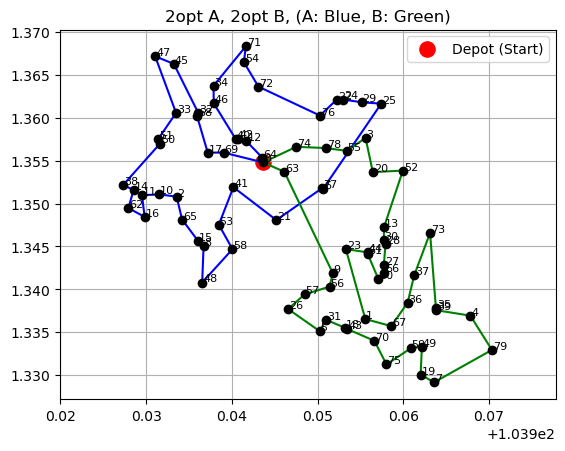

In [7]:

for i in range(len(optimized_route_a_2opt) - 1):
    connectpoints(coord_x, coord_y, optimized_route_a_2opt[i], optimized_route_a_2opt[i + 1], 'blue')  # Blue for Bus A

for i in range(len(optimized_route_b_2opt) - 1):
    connectpoints(coord_x, coord_y, optimized_route_b_2opt[i], optimized_route_b_2opt[i + 1], 'green')  # Green for Bus B

# Plot cities (stops) and depot (start stop)
plt.plot(coord_x, coord_y, 'ko')  # Plot cities as black dots
plt.scatter(coord_x[s], coord_y[s], color='red', s=120, label="Depot (Start)")  # Red marker for the depot (start stop)

# Label nodes (stop numbers) on the map
for idx, (x, y) in enumerate(zip(coord_x, coord_y)):
    plt.text(x + 0.0001, y + 0.0001, str(idx), fontsize=8)

# Add a title and display the plot
plt.title("2opt A, 2opt B, (A: Blue, B: Green)")
plt.axis('equal')  # Equal scaling of x and y axes
plt.grid(True)  # Enable grid for better visibility
plt.legend()  # Show legend for depot
plt.show()

### both A and B 3-opt

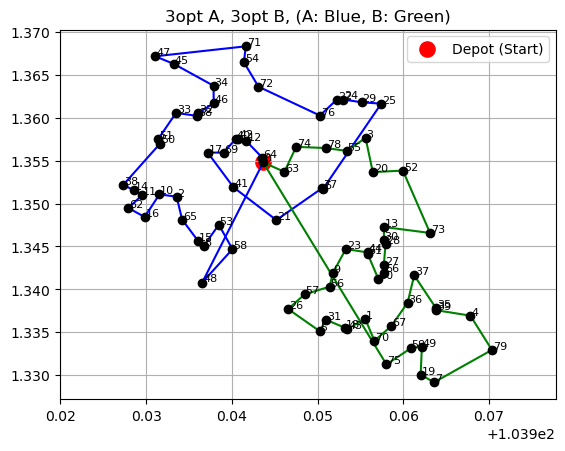

In [8]:

for i in range(len(optimized_route_a_3opt) - 1):
    connectpoints(coord_x, coord_y, optimized_route_a_3opt[i], optimized_route_a_3opt[i + 1], 'blue')  # Blue for Bus A

for i in range(len(optimized_route_b_3opt) - 1):
    connectpoints(coord_x, coord_y, optimized_route_b_3opt[i], optimized_route_b_3opt[i + 1], 'green')  # Green for Bus B

# Plot cities (stops) and depot (start stop)
plt.plot(coord_x, coord_y, 'ko')  # Plot cities as black dots
plt.scatter(coord_x[s], coord_y[s], color='red', s=120, label="Depot (Start)")  # Red marker for the depot (start stop)

# Label nodes (stop numbers) on the map
for idx, (x, y) in enumerate(zip(coord_x, coord_y)):
    plt.text(x + 0.0001, y + 0.0001, str(idx), fontsize=8)

# Add a title and display the plot
plt.title("3opt A, 3opt B, (A: Blue, B: Green)")
plt.axis('equal')  # Equal scaling of x and y axes
plt.grid(True)  # Enable grid for better visibility
plt.legend()  # Show legend for depot
plt.show()

# Simulated Annealing without Penalty

In [9]:
import time
import random
import math
import matplotlib.pyplot as plt


def total_cost(routeA, routeB, dist_matrix):
    dist_A = calculate_route_distance(routeA, dist_matrix)
    dist_B = calculate_route_distance(routeB, dist_matrix)
    return dist_A + dist_B 

def k_opt_perturb(routeA, routeB, dist_matrix):
    # Apply 2-opt or 3-opt randomly on one of the two routes
    routeA = list(routeA)
    routeB = list(routeB)
    
    if random.random() < 0.5:
        if random.random() < 0.5:
            routeA, _ = two_opt(routeA, dist_matrix)
        else:
            routeA, _ = three_opt(routeA, dist_matrix)
    else:
        if random.random() < 0.5:
            routeB, _ = two_opt(routeB, dist_matrix)
        else:
            routeB, _ = three_opt(routeB, dist_matrix)

    return routeA, routeB

def simulated_annealing_kopt(initial_A, initial_B, dist_matrix,T_init=100.0, alpha=0.99,
                        T_min=1e-3, max_iter=1000, max_time=3600):

    current_A = list(initial_A)
    current_B = list(initial_B)
    best_A = list(current_A)
    best_B = list(current_B)

    T = T_init

    start_time = time.time()
    time_history = [0]
    best_cost = total_cost(best_A, best_B, dist_matrix)
    current_cost = best_cost
    cost_history = [best_cost]

    for iter in range(max_iter):
        now = time.time()
        elapsed = now - start_time
        if elapsed > max_time:
            print("Reached time limit. Stopping early.")
            break

        neighbor_A, neighbor_B = k_opt_perturb(current_A, current_B,dist_matrix)
        neighbor_A, _ = two_opt(neighbor_A, dist_matrix)
        neighbor_B, _ = two_opt(neighbor_B, dist_matrix)

        new_cost = total_cost(neighbor_A, neighbor_B, dist_matrix)
        delta = new_cost - current_cost

        if delta < 0 or random.random() < math.exp(-delta / T):
            current_A, current_B = neighbor_A, neighbor_B
            current_cost = new_cost
            if new_cost < best_cost:
                best_A, best_B = list(neighbor_A), list(neighbor_B)
                best_cost = new_cost
                print(f"Iter {iter}: Improved cost = {best_cost:.5f} | Temp = {T:.4f}")

        T *= alpha
        time_history.append(elapsed)
        cost_history.append(best_cost)

        if T < T_min:
            print("Temperature too low. Stopping.")
            break

    return best_A, best_B, best_cost, cost_history, time_history

Iter 0: Improved cost = 0.26917 | Temp = 100.0000
Iter 1: Improved cost = 0.26428 | Temp = 99.5000
Iter 3: Improved cost = 0.26311 | Temp = 98.5075


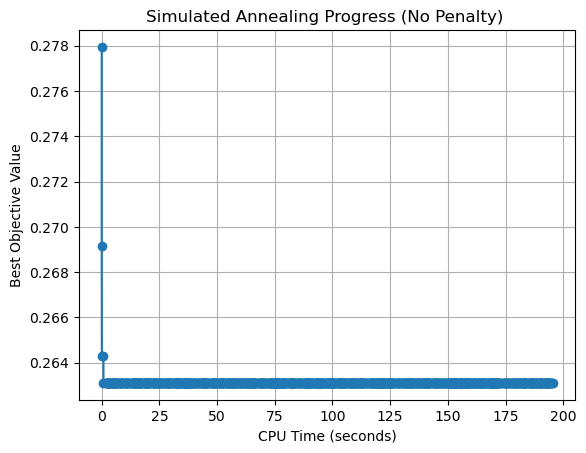

In [10]:
best_A, best_B, best_cost, cost_history, time_history = simulated_annealing_kopt(optimized_route_a_2opt, optimized_route_b_3opt,distancelct,
                        T_init=100.0, alpha=0.995,
                        T_min=1e-3, max_iter=1000, max_time=3600)


plt.plot(time_history, cost_history, marker='o')
plt.xlabel("CPU Time (seconds)")
plt.ylabel("Best Objective Value")
plt.title("Simulated Annealing Progress (No Penalty) ")
plt.grid(True)
plt.show()


[0, 64, 12, 42, 40, 46, 34, 45, 47, 71, 54, 72, 76, 22, 24, 29, 25, 6, 77, 21, 41, 53, 58, 48, 8, 15, 65, 2, 10, 16, 62, 11, 14, 38, 50, 51, 33, 32, 68, 17, 69, 0] [0, 63, 23, 61, 44, 13, 30, 28, 27, 66, 60, 9, 56, 57, 26, 5, 31, 18, 43, 1, 67, 70, 75, 59, 49, 19, 7, 79, 4, 39, 35, 36, 37, 73, 52, 20, 3, 55, 78, 74, 0]


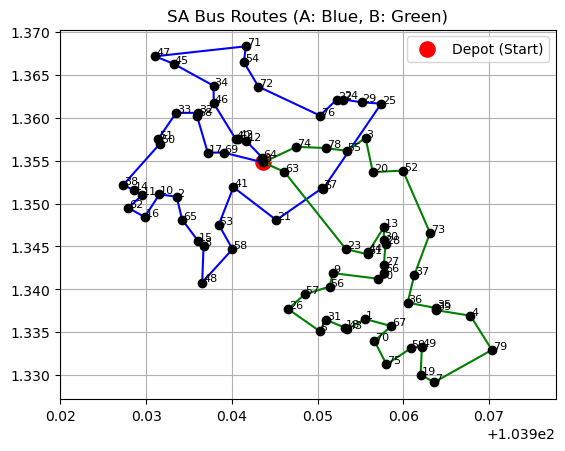

In [11]:
print(best_A, best_B)

# Plot the optimized routes for both Bus A and Bus B
# Note: Use the optimized routes
for i in range(len(best_A) - 1):
    connectpoints(coord_x, coord_y, best_A[i], best_A[i + 1], 'blue')  # Blue for Bus A

for i in range(len(best_B) - 1):
    connectpoints(coord_x, coord_y, best_B[i], best_B[i + 1], 'green')  # Green for Bus B

# Plot cities (stops) and depot (start stop)
plt.plot(coord_x, coord_y, 'ko')  # Plot cities as black dots
plt.scatter(coord_x[s], coord_y[s], color='red', s=120, label="Depot (Start)")  # Red marker for the depot (start stop)

# Label nodes (stop numbers) on the map
for idx, (x, y) in enumerate(zip(coord_x, coord_y)):
    plt.text(x + 0.0001, y + 0.0001, str(idx), fontsize=8)

# Add a title and display the plot
plt.title("SA Bus Routes (A: Blue, B: Green)")
plt.axis('equal')  # Equal scaling of x and y axes
plt.grid(True)  # Enable grid for better visibility
plt.legend()  # Show legend for depot
plt.show()

In [12]:
print("Bus A covers stops:", sorted(set(best_A)))
print("Bus B covers stops:", sorted(set(best_B)))
#no transfer of stops

Bus A covers stops: [0, 2, 6, 8, 10, 11, 12, 14, 15, 16, 17, 21, 22, 24, 25, 29, 32, 33, 34, 38, 40, 41, 42, 45, 46, 47, 48, 50, 51, 53, 54, 58, 62, 64, 65, 68, 69, 71, 72, 76, 77]
Bus B covers stops: [0, 1, 3, 4, 5, 7, 9, 13, 18, 19, 20, 23, 26, 27, 28, 30, 31, 35, 36, 37, 39, 43, 44, 49, 52, 55, 56, 57, 59, 60, 61, 63, 66, 67, 70, 73, 74, 75, 78, 79]


# Penalty

In [13]:
#PENALTY FEE
# Create mappings between stop numbers and their 0-indexed positions
stop_to_index = {stop_num: idx for idx, stop_num in enumerate(stops)}
index_to_stop = {idx: stop_num for idx, stop_num in enumerate(stops)}

def get_edge_type(u, v, bus_a_edges_set, bus_b_edges_set):
    on_a = (u, v) in bus_a_edges_set
    on_b = (u, v) in bus_b_edges_set

    if on_a and not on_b: return 'A_only'
    if on_b and not on_a: return 'B_only'
    if on_a and on_b: return 'Both'
    return 'None'

def shortest_path_with_transfers(start_node, end_node, n_stops, bus_a_edges_set, bus_b_edges_set, shared_stops):
    if start_node == end_node:
        return 0, 0, [start_node], []

    # State: (current_node, stops, transfers, last_bus, path, transfer_points)
    # last_bus: 'A', 'B', or None (start)
    queue = collections.deque([(start_node, 0, 0, None, [start_node], [])])
    
    # Visited: {(node, last_bus): min_stops}
    visited = {}

    min_stops = float('inf')
    min_transfers = float('inf')
    best_path = []
    best_transfer_points = []

    while queue:
        current_node, current_stops, current_transfers, last_bus, path, transfer_points = queue.popleft()

        # Skip if we've found a better path to this state
        if (current_node, last_bus) in visited and visited[(current_node, last_bus)] <= current_stops:
            continue
        visited[(current_node, last_bus)] = current_stops

        if current_node == end_node:
            if current_stops < min_stops or (current_stops == min_stops and current_transfers < min_transfers):
                min_stops = current_stops
                min_transfers = current_transfers
                best_path = path
                best_transfer_points = transfer_points
            continue

        for neighbor in range(n_stops):
            if current_node == neighbor:
                continue

            edge_type = get_edge_type(current_node, neighbor, bus_a_edges_set, bus_b_edges_set)
            
            if edge_type == 'None':
                continue

            # Option 1: Continue on Bus A or transfer to A
            if edge_type in ['A_only', 'Both']:
                new_transfers = current_transfers
                new_transfer_points = transfer_points.copy()
                new_last_bus = 'A'
                
                # If we're switching from B to A at a shared stop
                if last_bus == 'B' and current_node in shared_stops:
                    new_transfers += 1
                    new_transfer_points.append(current_node)
                
                queue.append((neighbor, current_stops + 1, new_transfers, new_last_bus, 
                            path + [neighbor], new_transfer_points))

            # Option 2: Continue on Bus B or transfer to B
            if edge_type in ['B_only', 'Both']:
                new_transfers = current_transfers
                new_transfer_points = transfer_points.copy()
                new_last_bus = 'B'
                
                # If we're switching from A to B at a shared stop
                if last_bus == 'A' and current_node in shared_stops:
                    new_transfers += 1
                    new_transfer_points.append(current_node)
                
                queue.append((neighbor, current_stops + 1, new_transfers, new_last_bus, 
                            path + [neighbor], new_transfer_points))

    return min_stops, min_transfers, best_path, best_transfer_points


def calculate_total_penalty(
    bus_a_route_indices,
    bus_b_route_indices,
    od_pairs_indices,
    n_stops,
    penalty_threshold_stops=5,
    penalty_cost_per_exceeding_stop=0.001
):
    total_penalty = 0.0
    transfer_counts_per_stop = collections.defaultdict(int)

    # Create edge sets
    bus_a_edges_set = set()
    bus_a_stops = set(bus_a_route_indices)
    for i in range(len(bus_a_route_indices) - 1):
        u, v = bus_a_route_indices[i], bus_a_route_indices[i+1]
        bus_a_edges_set.add((u, v))
        bus_a_edges_set.add((v, u))

    bus_b_edges_set = set()
    bus_b_stops = set(bus_b_route_indices)
    for i in range(len(bus_b_route_indices) - 1):
        u, v = bus_b_route_indices[i], bus_b_route_indices[i+1]
        bus_b_edges_set.add((u, v))
        bus_b_edges_set.add((v, u))

    # Find all shared stops (including depot at 0)
    shared_stops = bus_a_stops & bus_b_stops

    for origin_idx, dest_idx in od_pairs_indices:
        stops_traveled, num_transfers, path, transfer_points = \
            shortest_path_with_transfers(
                origin_idx, dest_idx, n_stops,
                bus_a_edges_set, bus_b_edges_set,
                shared_stops
            )

        if stops_traveled == float('inf'):
            # This should never happen since depot (0) connects both routes
            print(f"Error: No path found from {origin_idx} to {dest_idx}")
            total_penalty += 10  # High penalty for unreachable
        elif stops_traveled > penalty_threshold_stops:
            exceeding_stops = stops_traveled - penalty_threshold_stops
            total_penalty += exceeding_stops * penalty_cost_per_exceeding_stop
        
        for transfer_stop in transfer_points:
            transfer_counts_per_stop[transfer_stop] += 1

    return total_penalty, transfer_counts_per_stop
    


# Using the routes optimized by K-opt in the previous example
penalty_value, transfer_counts = calculate_total_penalty(
    optimized_route_a_2opt,
    optimized_route_b_2opt,
    od_pairs, # Now using the actual OD pairs
    n,
    penalty_threshold_stops=30, # Example: penalize if travel exceeds 30 stops
    penalty_cost_per_exceeding_stop=0.001
)
print(f"Total Passenger Travel Penalty: {penalty_value:.8f}")

print("\n--- Transfer Statistics ---")
if transfer_counts:
    print("Transfers occurred at the following stops:")
    for stop_idx, count in sorted(transfer_counts.items(), key=lambda item: item[1], reverse=True):
        print(f"  Stop {index_to_stop[stop_idx]} (Index: {stop_idx}): {count} transfers")
else:
    print("No transfers were detected for the given routes and OD pairs.")

Total Passenger Travel Penalty: 0.06000000

--- Transfer Statistics ---
Transfers occurred at the following stops:
  Stop 0 (Index: 0): 94 transfers


# Simulated Annealling with Penalty

In [14]:
def penalty_total_cost(routeA, routeB, dist_matrix, od_pairs, n, penalty_weight):
    dist_A = calculate_route_distance(routeA, dist_matrix)
    dist_B = calculate_route_distance(routeB, dist_matrix)
    total_penalty, _ = calculate_total_penalty(
        routeA, routeB, od_pairs, n,
        penalty_threshold_stops=3,
        penalty_cost_per_exceeding_stop=penalty_weight
    )
    return dist_A + dist_B + total_penalty
    
def simulated_annealing_penalty(initial_A, initial_B, dist_matrix, od_pairs, n,
                              penalty_weight_init=0.001, T_init=100.0, alpha=0.99,
                              T_min=1e-3, max_iter=1000, max_time=3600,
                              penalty_increase_factor=2.0, penalty_decrease_factor=0.5,
                              penalty_history_window=10):

    current_A = list(initial_A)
    current_B = list(initial_B)
    best_A = list(current_A)
    best_B = list(current_B)

    lam = penalty_weight_init
    T = T_init
    penalty_history = []

    start_time = time.time()
    time_history = [0]
    best_cost = penalty_total_cost(best_A, best_B, dist_matrix, od_pairs, n, lam)
    current_cost = best_cost
    cost_history = [best_cost]

    for iter in range(max_iter):
        elapsed = time.time() - start_time
        if elapsed > max_time:
            print("Reached time limit. Stopping early.")
            break

        # K-opt-based perturbation
        neighbor_A, neighbor_B = k_opt_perturb(current_A, current_B, dist_matrix)

        new_cost = penalty_total_cost(neighbor_A, neighbor_B, dist_matrix, od_pairs, n, lam)
        delta = new_cost - current_cost

        if delta < 0 or random.random() < math.exp(-delta / T):
            current_A, current_B = neighbor_A, neighbor_B
            current_cost = new_cost
            if new_cost < best_cost:
                best_A, best_B = list(neighbor_A), list(neighbor_B)
                best_cost = new_cost
                print(f"Iter {iter}: Improved cost = {best_cost:.2f} | λ = {lam:.2f} | Temp = {T:.4f}")

        # Feasibility tracking (0 penalty means fully feasible)
        penalty_value, _ = calculate_total_penalty(current_A, current_B, od_pairs, n,
                                                   penalty_threshold_stops=30,
                                                   penalty_cost_per_exceeding_stop=0.001)
        penalty_history.append(penalty_value == 0.0)

        if len(penalty_history) >= penalty_history_window:
            recent = penalty_history[-penalty_history_window:]
            if all(recent):
                lam *= penalty_decrease_factor
            elif not any(recent):
                lam *= penalty_increase_factor
            penalty_history = []

        T *= alpha
        time_history.append(elapsed)
        cost_history.append(best_cost)

        if T < T_min:
            print("Temperature too low. Stopping.")
            break

    return best_A, best_B, best_cost, cost_history, time_history


Iter 1: Improved cost = 2.78 | λ = 0.00 | Temp = 99.0000


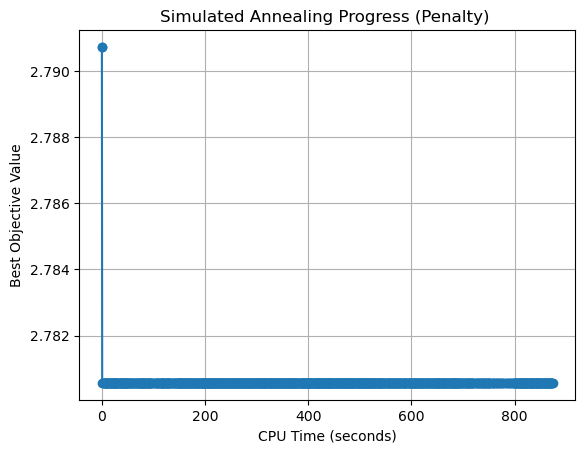

In [15]:
penalty_best_A, penalty_best_B, penalty_best_cost, penalty_cost_history, penalty_time_history = simulated_annealing_penalty(optimized_route_a_2opt, optimized_route_b_2opt,distancelct, od_pairs, n,
                        penalty_weight_init=0.001, T_init=100.0, alpha=0.99,
                        T_min=1e-3, max_iter=1000, penalty_increase_factor=2.0,
                        penalty_decrease_factor=0.5, penalty_history_window=10, max_time=3600)

plt.plot(penalty_time_history, penalty_cost_history, marker='o')
plt.xlabel("CPU Time (seconds)")
plt.ylabel("Best Objective Value")
plt.title("Simulated Annealing Progress (Penalty) ")
plt.grid(True)
plt.show()


[0, 64, 12, 42, 40, 46, 34, 45, 47, 71, 54, 72, 76, 22, 24, 29, 25, 6, 77, 21, 41, 53, 58, 48, 8, 15, 65, 2, 10, 16, 62, 11, 14, 38, 50, 51, 33, 32, 68, 17, 69, 0] [0, 63, 9, 56, 57, 26, 5, 31, 18, 43, 70, 75, 59, 49, 19, 7, 79, 4, 39, 35, 73, 37, 36, 67, 1, 23, 44, 61, 60, 66, 27, 28, 30, 13, 52, 20, 3, 55, 78, 74, 0]


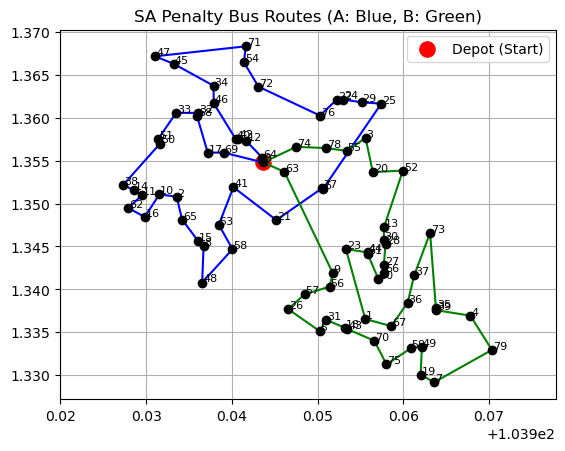

In [19]:
print(penalty_best_A, penalty_best_B)

# Plot the optimized routes for both Bus A and Bus B
# Note: Use the optimized routes
for i in range(len(penalty_best_A) - 1):
    connectpoints(coord_x, coord_y, penalty_best_A[i], penalty_best_A[i + 1], 'blue')  # Blue for Bus A

for i in range(len(penalty_best_B) - 1):
    connectpoints(coord_x, coord_y,penalty_best_B[i], penalty_best_B[i + 1], 'green')  # Green for Bus B

# Plot cities (stops) and depot (start stop)
plt.plot(coord_x, coord_y, 'ko')  # Plot cities as black dots
plt.scatter(coord_x[s], coord_y[s], color='red', s=120, label="Depot (Start)")  # Red marker for the depot (start stop)

# Label nodes (stop numbers) on the map
for idx, (x, y) in enumerate(zip(coord_x, coord_y)):
    plt.text(x + 0.0001, y + 0.0001, str(idx), fontsize=8)

# Add a title and display the plot
plt.title("SA Penalty Bus Routes (A: Blue, B: Green)")
plt.axis('equal')  # Equal scaling of x and y axes
plt.grid(True)  # Enable grid for better visibility
plt.legend()  # Show legend for depot
plt.show()